# Fourier Neural Operator

This notebook implements the **Fourier Neural Operator (FNO)** surrogate (Section 4.2) for the parametric
diffusion problem.

**Contrast with PCA-Net.**  PCA-Net first compresses the output to a low-dimensional PCA space,
then trains a feed-forward network on the coefficients.  The FNO instead approximates the
solution operator $\mathcal{G} : x \mapsto y$ directly in (discretised) function space, receiving the full
coefficient field $x(\eta)$ on the grid and outputting the full solution $y(\eta)$:
$$
  \hat{\mathcal{G}} = \text{Project} \circ L_{n} \circ \cdots \circ L_1 \circ \text{Lift}.
$$
No explicit input/output encoder is needed.  The key component of each layer $L_\ell$ is a
**global spectral convolution** in the Fourier domain, which acts on all grid points
simultaneously.

In [1]:
import time
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import error

from importer import import_notebook
import_notebook('0_Diffusion.ipynb', globals())        # provides: Grid, Diffusion
import_notebook('1_Representation.ipynb', globals())  # provides: Encoder

In [2]:
d_param  = 50                # sine-series parameter dimension
decay    = 2                 # smoothness decay
d_hidden = 16                # hidden channels in each FNO layer
n_modes  = 16                # Fourier modes retained per layer
n_layers = 2                 # number of FNO layers
n_epochs = 200               # training epochs per run
n_test   = 200               # number of test samples
n_trains = [200, 500, 1000]  # number of training samples
n_max    = max(n_trains)     # maximal number of training samples
grid     = Grid(128)         # discretisation of the PDE
rng      = np.random.default_rng(0)

## 1. Architecture

The FNO consists of three components:

1. **Lift** - a pointwise linear map that lifts the input (coefficient field with appended spatial coordinate) to $d_\mathrm{hidden}$ channels.
2. **FNO layers** - each layer applies a spectral convolution and a bypass in parallel:
$$
  L_\ell(x) = \mathrm{GELU}\left(
    \underbrace{K_\ell x}_{\text{spectral conv}} +
    \underbrace{W_\ell x}_{\text{bypass}}
  \right).
$$
   The spectral convolution $K_\ell$ applies a learnable complex weight matrix to the lowest
   `n_modes` Fourier modes of $x$, making it a **global, mesh-invariant** operation.
   $W_\ell$ is a local pointwise linear map.
3. **Project** - a two-layer MLP that maps $d_\mathrm{hidden}$ channels back to the scalar output.

In [3]:
#EXPORT

class SpectralConv1d(nn.Module):
    """
    Learnable complex multiplication in the lowest n_modes Fourier modes.

    Weight tensor W = W_re + i*W_im has shape (d_in, d_out, n_modes).
    For each mode k:  out[k] = W[:, :, k] * x_ft[k]   (complex matrix-vector product).
    """

    def __init__(self, d_in, d_out, n_modes):
        super().__init__()
        self.n_modes = n_modes
        self.W_re = nn.Parameter(torch.empty(d_in, d_out, n_modes).normal_(std=0.02))
        self.W_im = nn.Parameter(torch.empty(d_in, d_out, n_modes).normal_(std=0.02))

    def forward(self, x):
        # x: (batch, N, d_in)
        N       = x.shape[1]
        n_modes = min(self.n_modes, N // 2 + 1)
        x_ft    = torch.fft.rfft(x, dim=1)[:, :n_modes, :]     # (batch, n_modes, d_in)
        out_re  = (torch.einsum('bkc,cdk->bkd', x_ft.real, self.W_re)
                 - torch.einsum('bkc,cdk->bkd', x_ft.imag, self.W_im))
        out_im  = (torch.einsum('bkc,cdk->bkd', x_ft.real, self.W_im)
                 + torch.einsum('bkc,cdk->bkd', x_ft.imag, self.W_re))
        out_ft  = torch.zeros(x.shape[0], N // 2 + 1, self.W_re.shape[1],
                              dtype=torch.cfloat, device=x.device)
        out_ft[:, :n_modes] = torch.complex(out_re, out_im)
        return torch.fft.irfft(out_ft, n=N, dim=1)              # (batch, N, d_out)


class FNONetwork(nn.Module):
    """
    1D Fourier Neural Operator:  lift -> n_layers FNO layers -> project.

    Each FNO layer applies spectral_conv(x) + bypass(x) followed by GELU,
    with spectral_conv a global operation in Fourier space and bypass a local pointwise map.

    Input: scalar field of shape (batch, N); spatial coordinate appended as second channel before lifting.
    Output: scalar field of shape (batch, N).
    """

    def __init__(self, d_hidden=32, n_modes=16, n_layers=4):
        super().__init__()
        self.lift     = nn.Linear(2, d_hidden)
        self.spectral = nn.ModuleList([SpectralConv1d(d_hidden, d_hidden, n_modes)
                                       for _ in range(n_layers)])
        self.bypass   = nn.ModuleList([nn.Linear(d_hidden, d_hidden, bias=False)
                                       for _ in range(n_layers)])
        self.project  = nn.Sequential(nn.Linear(d_hidden, d_hidden),
                                      nn.GELU(),
                                      nn.Linear(d_hidden, 1))

    def forward(self, x):
        x_coord = torch.linspace(0, 1, x.shape[1], device=x.device).unsqueeze(0).expand(x.shape[0], -1)
        x = self.lift(torch.stack([x, x_coord], dim=-1))       # (batch, N, 2) -> (batch, N, d_hidden)
        for spec, lin in zip(self.spectral, self.bypass):
            x = nn.functional.gelu(spec(x) + lin(x))           # FNO layer
        return self.project(x).squeeze(-1)                      # -> (batch, N)


class FNO:
    """
    Training / inference wrapper around FNONetwork.

    Data dicts use keys:
        'x' : (n, N+1) array  -  input field  (diffusion coefficient on grid.nodes_bd)
        'y' : (n, N+1) array  -  target field (PDE solution on grid.nodes_bd)
    """

    def __init__(self, d_hidden=32, n_modes=16, n_layers=4):
        self.network = FNONetwork(d_hidden=d_hidden, n_modes=n_modes, n_layers=n_layers)

    def forward(self, x):
        """ Evaluate the FNO.  x: numpy array -> numpy array. """
        self.network.eval()
        with torch.no_grad():
            return self.network(torch.tensor(x, dtype=torch.float32)).numpy()

    def train(self, data_train, data_test=None, n_epochs=500, verbose=True):
        """
        Train with Adam (lr=1e-3, batch_size=32).
        Returns loss history dict with keys 'train' and 'test'.
        """
        t0       = time.perf_counter()
        to_t     = lambda a: torch.tensor(a, dtype=torch.float32)
        dl_train = DataLoader(TensorDataset(to_t(data_train['x']), to_t(data_train['y'])),
                              batch_size=32, shuffle=True)
        dl_test  = None
        if data_test is not None:
            dl_test = DataLoader(TensorDataset(to_t(data_test['x']), to_t(data_test['y'])),
                                 batch_size=len(data_test['x']))

        loss_fn   = nn.MSELoss()
        optimizer = optim.Adam(self.network.parameters(), lr=1e-3)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
        history   = {'train': np.zeros(n_epochs), 'test': np.zeros(n_epochs)}

        for epoch in range(n_epochs):
            # test evaluation (before this epoch's updates)
            if dl_test is not None:
                self.network.eval()
                with torch.no_grad():
                    for bx, by in dl_test:
                        history['test'][epoch] = loss_fn(self.network(bx), by).item()

            # training step
            self.network.train()
            for bx, by in dl_train:
                optimizer.zero_grad()
                loss = loss_fn(self.network(bx), by)
                loss.backward()
                optimizer.step()
                history['train'][epoch] += loss.item() * len(bx)
            history['train'][epoch] /= len(dl_train.dataset)
            scheduler.step()

            if verbose and (epoch + 1) % 50 == 0:
                print(f'  epoch {epoch+1:4d}/{n_epochs}'
                      f'  train={history["train"][epoch]:.3e}'
                      f'  test={history["test"][epoch]:.3e}')

        if verbose:
            print(f'Training (n={len(dl_train.dataset)}, {n_epochs} epochs):  {time.perf_counter() - t0:.0f}s')
        return history

## 2. Data and Learning Curve

We generate all samples up front - they are reused across all experiments below.
The FNO takes the evaluated coefficient field $x(\eta)$ on `grid.nodes_bd` as input
and predicts $y(\eta)$ on the same grid; no PCA encoding is applied.

In [4]:
# Set up training and test data
xb_all = rng.uniform(-1., 1., (n_max + n_test, d_param))
x_all = np.array([Encoder(parameter=xb, decay=decay)(grid.nodes_bd) for xb in xb_all])
y_all = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_all])

n_train_ex = 500
data_tr_ex = {'x': x_all[:n_train_ex], 'y': y_all[:n_train_ex]}
data_te_ex = {'x': x_all[n_max:],      'y': y_all[n_max:]}

model_ex = FNO(d_hidden=d_hidden, n_modes=n_modes, n_layers=n_layers)
history  = model_ex.train(data_tr_ex, data_te_ex, n_epochs=n_epochs, verbose=True)

  epoch   50/200  train=1.841e-05  test=2.031e-05
  epoch  100/200  train=5.864e-06  test=6.827e-06
  epoch  150/200  train=3.841e-06  test=4.692e-06
  epoch  200/200  train=3.554e-06  test=4.425e-06
Training (n=500, 200 epochs):  136s


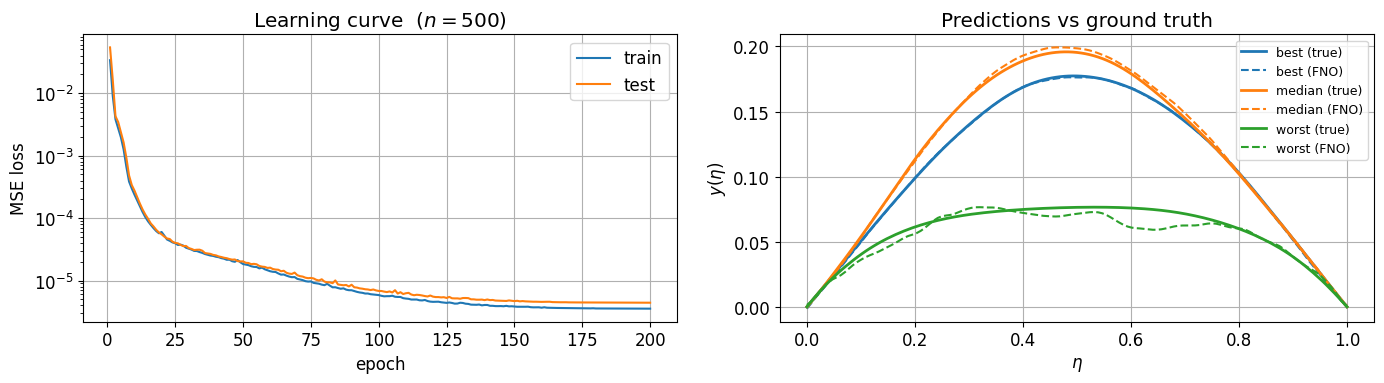

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# -- learning curve --
epochs = np.arange(1, n_epochs + 1)
axs[0].semilogy(epochs, history['train'], label='train')
axs[0].semilogy(epochs, history['test'],  label='test')
axs[0].set_xlabel('epoch'); axs[0].set_ylabel('MSE loss')
axs[0].set_title(f'Learning curve  ($n={n_train_ex}$)')
axs[0].legend(); axs[0].grid()

# -- example predictions --
y_pred_ex = model_ex.forward(data_te_ex['x'])
rel_l2_ex = error.l2_rel(data_te_ex['y'], y_pred_ex, per_sample=True)
idx_med  = np.argsort(rel_l2_ex)[len(rel_l2_ex) // 2]
idx_best = np.argmin(rel_l2_ex)
idx_worst = np.argmax(rel_l2_ex)
for idx, label in [(idx_best, 'best'), (idx_med, 'median'), (idx_worst, 'worst')]:
    line, = axs[1].plot(grid.nodes_bd, data_te_ex['y'][idx],    lw=2,   label=f'{label} (true)')
    axs[1].plot(grid.nodes_bd, y_pred_ex[idx], lw=1.5, ls='--', label=f'{label} (FNO)', color=line.get_color())
axs[1].set_xlabel(r'$\eta$'); axs[1].set_ylabel(r'$y(\eta)$')
axs[1].set_title('Predictions vs ground truth')
axs[1].legend(fontsize=9); axs[1].grid()

plt.tight_layout()
plt.show()

## 3. Convergence with Training Data Size

We study how the FNO prediction error decreases as the number of training samples $n$ grows,
for $\alpha = 2$ (fixed to limit runtime).
For each $n$ a fresh FNO is trained from scratch for `n_epochs` epochs.

**Note:** each training run takes several minutes on CPU; the total runtime for this cell is
printed after each run.

In [6]:
results  = {}  # n_train -> error
t_total  = time.perf_counter()

for n_train in n_trains:
    data_tr = {'x': x_all[:n_train], 'y': y_all[:n_train]}
    model   = FNO(d_hidden=d_hidden, n_modes=n_modes, n_layers=n_layers)
    model.train(data_tr, n_epochs=n_epochs)
    err     = error.l2_rel(data_te_ex['y'], model.forward(data_te_ex['x']))
    results[n_train] = err
    print(f'n={n_train:5d}  ->  rel-L2 = {err:.3e}')

print(f'\nTotal convergence study:  {time.perf_counter() - t_total:.0f}s')

  epoch   50/200  train=2.783e-05  test=0.000e+00
  epoch  100/200  train=9.204e-06  test=0.000e+00
  epoch  150/200  train=5.679e-06  test=0.000e+00
  epoch  200/200  train=5.167e-06  test=0.000e+00
Training (n=200, 200 epochs):  35s
n=  200  ->  rel-L2 = 2.339e-02
  epoch   50/200  train=7.451e-06  test=0.000e+00
  epoch  100/200  train=2.523e-06  test=0.000e+00
  epoch  150/200  train=1.817e-06  test=0.000e+00
  epoch  200/200  train=1.682e-06  test=0.000e+00
Training (n=500, 200 epochs):  77s
n=  500  ->  rel-L2 = 1.462e-02
  epoch   50/200  train=3.227e-06  test=0.000e+00
  epoch  100/200  train=1.204e-06  test=0.000e+00
  epoch  150/200  train=8.030e-07  test=0.000e+00
  epoch  200/200  train=7.162e-07  test=0.000e+00
Training (n=1000, 200 epochs):  170s
n= 1000  ->  rel-L2 = 8.938e-03

Total convergence study:  282s


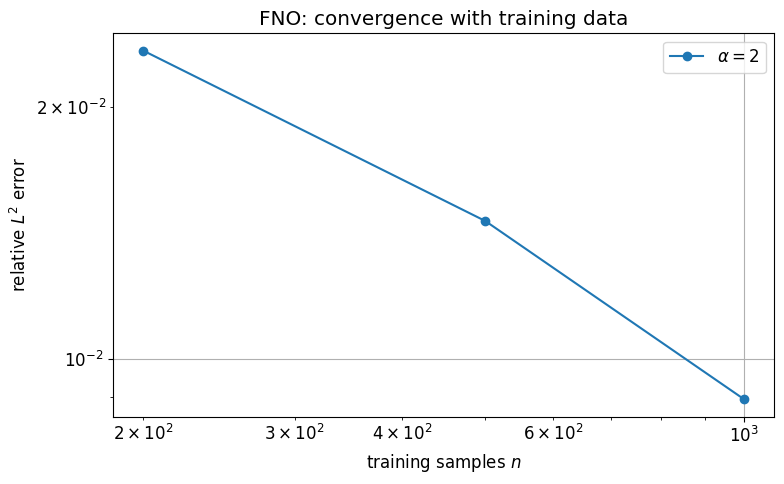

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ns   = list(results.keys())
errs = [results[n] for n in ns]
ax.loglog(ns, errs, marker='o', label=rf'$\alpha = {decay}$')
ax.set_title('FNO: convergence with training data')
ax.set_xlabel('training samples $n$'); ax.set_ylabel('relative $L^2$ error')
ax.legend(); ax.grid(); plt.tight_layout()
plt.show()